# Lab 2 – Exercise 3: MLP with the MNIST dataset

Part 0 is the original (baseline) model. Then:
- **(a)** improve test accuracy by changing hyperparameters
- **(b)** add L1 and L2 regularization and retrain
- **(c)** visualize class-wise test performance with a confusion matrix

> Tip: in Colab use *Runtime → Change runtime type → T4 GPU* to train faster.

## Part 0 – Baseline model (original notebook)
Architecture 784 → 64 → 64 → 32 → 10, Adam, batch size 32, 10 epochs.

In [1]:
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras.utils import to_categorical
from matplotlib import pyplot as plt
import numpy as np
import tensorflow as tf
tf.keras.utils.set_random_seed(42)   # reproducible results


Load the MNIST dataset

In [2]:
(train_data,train_target),(test_data,test_target) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Visualize the dataset

Target labels:  [4 0 0 8 3 6 3 1 6 4]


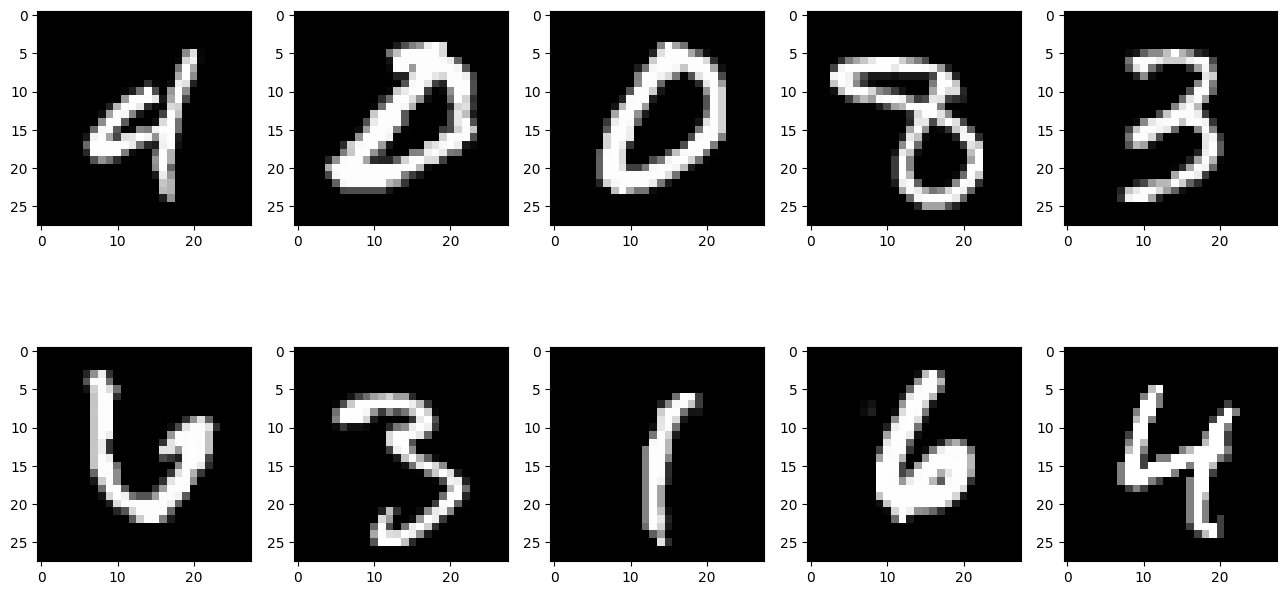

In [3]:
fig, axs = plt.subplots(2, 5, figsize=(16,8))
random_numbers = np.random.randint(0, 60000, 10)
print('Target labels: ',train_target[random_numbers])
for idx, ax in enumerate(axs.ravel()):
    ax.imshow(train_data[random_numbers[idx]],cmap='gray')
plt.show()

Pre-processing stage

In [4]:
new_train_data = train_data/255.0
new_test_data=test_data/255.0

new_train_target = to_categorical(train_target)
new_test_target = to_categorical(test_target)

Create the Model architecture

In [5]:
model=Sequential()

model.add(Flatten(input_shape=(28,28)))

model.add(Dense(64,activation='relu'))
model.add(Dense(64,input_dim=64,activation='relu'))
model.add(Dense(32,input_dim=64,activation='relu'))
model.add(Dense(10,input_dim=32,activation='softmax'))
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [6]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,810 (221.91 KB)

 Trainable params: 56,810 (221.91 KB)

 Non-trainable params: 0 (0.00 B)

Train the model

In [7]:
train_info = model.fit(new_train_data , new_train_target , epochs = 10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 3ms/step - accuracy: 0.9144 - loss: 0.2825
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9627 - loss: 0.1236
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9729 - loss: 0.0899
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9777 - loss: 0.0709
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9820 - loss: 0.0582
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9850 - loss: 0.0478
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9871 - loss: 0.0397
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9874 - loss: 0.0393
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9893 - loss: 0.0319
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9889 - loss: 0.0325


Plot the loss and accuracy graphs

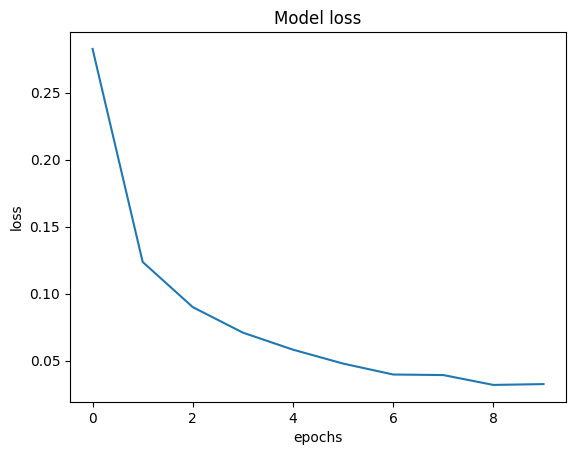

In [8]:
plt.plot(train_info.history['loss'])
plt.xlabel('epochs')
plt.ylabel('loss')
plt.title('Model loss')
plt.show()

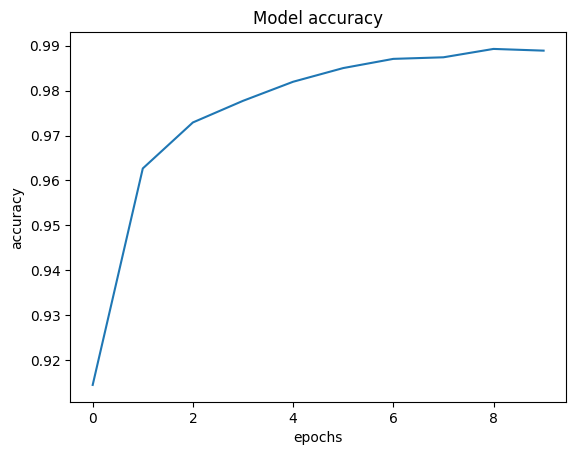

In [9]:
plt.plot(train_info.history['accuracy'])
plt.xlabel('epochs')
plt.ylabel('accuracy')
plt.title('Model accuracy')
plt.show()

Test the performance of Model

In [10]:
loss, acc = model.evaluate(new_test_data , new_test_target)
print(f'Loss of the Test dataset is: {loss}\nAccuracy of the test dataset is: {acc}')

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9690 - loss: 0.1244
Loss of the Test dataset is: 0.12444305419921875
Accuracy of the test dataset is: 0.968999981880188


Save the model weights

In [11]:
# Keras 3 (current Colab) requires weight files to end in '.weights.h5'
model.save_weights('MNIST_WEIGHTS_V1.weights.h5')

---
## Part (a) – Improving test accuracy by changing hyperparameters

### Step 1: quick hyperparameter experiments
Each configuration is trained for 5 epochs with 10% of the training data held out for validation, so they can be compared fairly. The test set is **not** used for choosing hyperparameters.

In [12]:
from tensorflow.keras.layers import Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

baseline_test_acc = acc   # from the baseline evaluation above

def build_model(hidden_units=(64, 64, 32), learning_rate=0.001, dropout=0.0, reg=None):
    """Builds an MLP. reg is a Keras regularizer applied to every hidden Dense layer."""
    m = Sequential()
    m.add(Input(shape=(28, 28)))
    m.add(Flatten())
    for units in hidden_units:
        m.add(Dense(units, activation='relu', kernel_regularizer=reg))
        if dropout > 0:
            m.add(Dropout(dropout))
    m.add(Dense(10, activation='softmax'))
    m.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=learning_rate), metrics=['accuracy'])
    return m

experiments = [
    dict(name='Baseline (64-64-32, lr=0.001, bs=32)', hidden_units=(64,64,32),  learning_rate=0.001, batch_size=32,  dropout=0.0),
    dict(name='Wider (256-128)',                      hidden_units=(256,128),   learning_rate=0.001, batch_size=32,  dropout=0.0),
    dict(name='Wider + dropout 0.2',                  hidden_units=(256,128),   learning_rate=0.001, batch_size=32,  dropout=0.2),
    dict(name='Wider + dropout, bs=128',              hidden_units=(256,128),   learning_rate=0.001, batch_size=128, dropout=0.2),
    dict(name='Wider + dropout, lr=0.01',             hidden_units=(256,128),   learning_rate=0.01,  batch_size=128, dropout=0.2),
    dict(name='Larger (512-256-128) + dropout',       hidden_units=(512,256,128), learning_rate=0.001, batch_size=128, dropout=0.2),
]

exp_results = []
for e in experiments:
    m = build_model(e['hidden_units'], e['learning_rate'], e['dropout'])
    h = m.fit(new_train_data, new_train_target, epochs=5, batch_size=e['batch_size'],
              validation_split=0.1, verbose=0)
    exp_results.append((e['name'], h.history['accuracy'][-1], h.history['val_accuracy'][-1]))
    print(f"{e['name']:<38} train acc = {h.history['accuracy'][-1]:.4f}   val acc = {h.history['val_accuracy'][-1]:.4f}")

Baseline (64-64-32, lr=0.001, bs=32)   train acc = 0.9823   val acc = 0.9707
Wider (256-128)                        train acc = 0.9894   val acc = 0.9733
Wider + dropout 0.2                    train acc = 0.9788   val acc = 0.9787
Wider + dropout, bs=128                train acc = 0.9778   val acc = 0.9798
Wider + dropout, lr=0.01               train acc = 0.9541   val acc = 0.9747
Larger (512-256-128) + dropout         train acc = 0.9816   val acc = 0.9738


### Step 2: train the final improved model
Based on the experiments, the improved model uses:

| Hyperparameter | Baseline | Improved |
|---|---|---|
| Hidden layers | 64 → 64 → 32 | 512 → 256 → 128 |
| Dropout | none | 0.2 after each hidden layer |
| Batch size | 32 | 128 |
| Epochs | 10 (fixed) | up to 30 with **EarlyStopping** (patience 4, restores best weights) |
| Learning rate | 0.001 fixed | 0.001 with **ReduceLROnPlateau** (halves the rate when validation loss stops improving) |
| Validation | none | 10% validation split |

Wider layers give more capacity, dropout reduces overfitting, and early stopping / LR scheduling stop training at the best point instead of after an arbitrary number of epochs.

In [13]:
improved_model = build_model(hidden_units=(512, 256, 128), learning_rate=0.001, dropout=0.2)
improved_model.summary()

callbacks = [
    EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5),
]
improved_info = improved_model.fit(new_train_data, new_train_target, epochs=30, batch_size=128,
                                   validation_split=0.1, callbacks=callbacks)

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_7 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_25 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_26 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_27 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 567,434 (2.16 MB)

 Trainable params: 567,434 (2.16 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9014 - loss: 0.3229 - val_accuracy: 0.9688 - val_loss: 0.1053 - learning_rate: 0.0010
Epoch 2/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9602 - loss: 0.1315 - val_accuracy: 0.9753 - val_loss: 0.0859 - learning_rate: 0.0010
Epoch 3/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9722 - loss: 0.0912 - val_accuracy: 0.9780 - val_loss: 0.0770 - learning_rate: 0.0010
Epoch 4/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9771 - loss: 0.0709 - val_accuracy: 0.9782 - val_loss: 0.0739 - learning_rate: 0.0010
Epoch 5/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9814 - loss: 0.0610 - val_accuracy: 0.9793 - val_loss: 0.0728 - learning_rate: 0.0010
Epoch 6/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9838 - loss: 0.0508 - val_accuracy: 0.9795 - val_loss: 0.0731 - learning_rate: 0.0010
Epoch 7/30
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9859 - loss: 0.0430 -

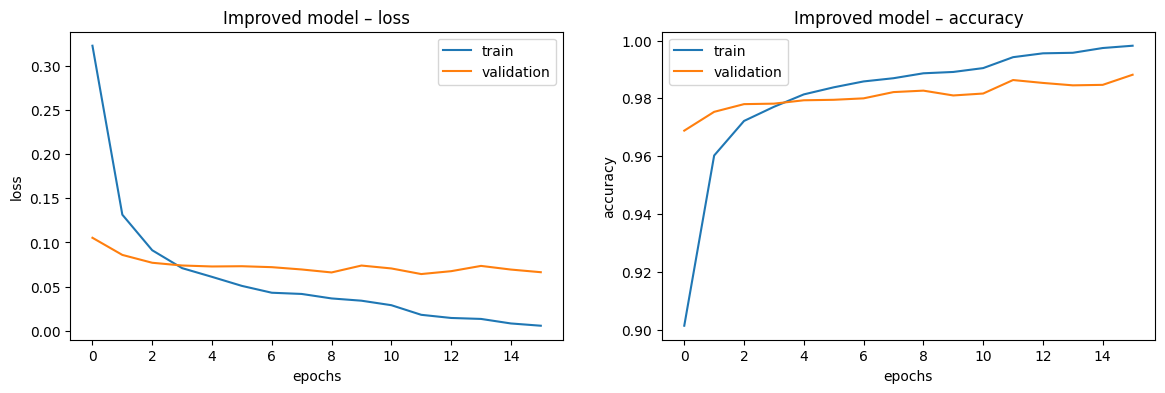

In [14]:
def plot_history(history, title):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    ax[0].plot(history.history['loss'], label='train')
    ax[0].plot(history.history['val_loss'], label='validation')
    ax[0].set_title(title + ' – loss'); ax[0].set_xlabel('epochs'); ax[0].set_ylabel('loss'); ax[0].legend()
    ax[1].plot(history.history['accuracy'], label='train')
    ax[1].plot(history.history['val_accuracy'], label='validation')
    ax[1].set_title(title + ' – accuracy'); ax[1].set_xlabel('epochs'); ax[1].set_ylabel('accuracy'); ax[1].legend()
    plt.show()

plot_history(improved_info, 'Improved model')

In [15]:
improved_loss, improved_acc = improved_model.evaluate(new_test_data, new_test_target)
print(f'Baseline test accuracy : {baseline_test_acc:.4f}')
print(f'Improved test accuracy : {improved_acc:.4f}')
print(f'Improvement            : {(improved_acc - baseline_test_acc)*100:+.2f} percentage points')

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9837 - loss: 0.0640
Baseline test accuracy : 0.9690
Improved test accuracy : 0.9837
Improvement            : +1.47 percentage points


---
## Part (b) – Adding L1 and L2 regularization

Regularization adds a penalty on the size of the weights to the loss:

- **L1:** loss + λ₁ Σ|w|, which pushes many weights to exactly zero (sparse weights)
- **L2 (weight decay):** loss + λ₂ Σw², which keeps all weights small
- **L1 + L2 (elastic net):** both penalties together

The penalty discourages the network from memorising the training data, which reduces overfitting (a smaller gap between training and validation accuracy). Three models are trained with the improved architecture: L1 only, L2 only, and L1 + L2.

In [16]:
reg_configs = {
    'L1 (1e-5)':          regularizers.l1(1e-5),
    'L2 (1e-4)':          regularizers.l2(1e-4),
    'L1+L2 (1e-5, 1e-4)': regularizers.l1_l2(l1=1e-5, l2=1e-4),
}

reg_models, reg_histories, reg_results = {}, {}, {}
for name, reg in reg_configs.items():
    print(f'\n===== Training model with {name} regularization =====')
    m = build_model(hidden_units=(512, 256, 128), learning_rate=0.001, dropout=0.2, reg=reg)
    h = m.fit(new_train_data, new_train_target, epochs=30, batch_size=128, validation_split=0.1,
              callbacks=[EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
                         ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5)],
              verbose=2)
    test_loss, test_acc = m.evaluate(new_test_data, new_test_target, verbose=0)
    reg_models[name], reg_histories[name] = m, h
    reg_results[name] = (h.history['accuracy'][-1], h.history['val_accuracy'][-1], test_acc)
    print(f'{name}: test accuracy = {test_acc:.4f}')


===== Training model with L1 (1e-5) regularization =====
Epoch 1/30
422/422 - 9s - 21ms/step - accuracy: 0.9018 - loss: 0.4871 - val_accuracy: 0.9677 - val_loss: 0.2564 - learning_rate: 0.0010
Epoch 2/30
422/422 - 1s - 3ms/step - accuracy: 0.9623 - loss: 0.2820 - val_accuracy: 0.9742 - val_loss: 0.2330 - learning_rate: 0.0010
Epoch 3/30
422/422 - 1s - 3ms/step - accuracy: 0.9701 - loss: 0.2424 - val_accuracy: 0.9777 - val_loss: 0.2192 - learning_rate: 0.0010
Epoch 4/30
422/422 - 1s - 3ms/step - accuracy: 0.9754 - loss: 0.2208 - val_accuracy: 0.9765 - val_loss: 0.2121 - learning_rate: 0.0010
Epoch 5/30
422/422 - 1s - 3ms/step - accuracy: 0.9790 - loss: 0.2054 - val_accuracy: 0.9782 - val_loss: 0.2144 - learning_rate: 0.0010
Epoch 6/30
422/422 - 1s - 3ms/step - accuracy: 0.9806 - loss: 0.1974 - val_accuracy: 0.9820 - val_loss: 0.1986 - learning_rate: 0.0010
Epoch 7/30
422/422 - 1s - 3ms/step - accuracy: 0.9823 - loss: 0.1877 - val_accuracy: 0.9807 - val_loss: 0.2003 - learning_rate: 0.0

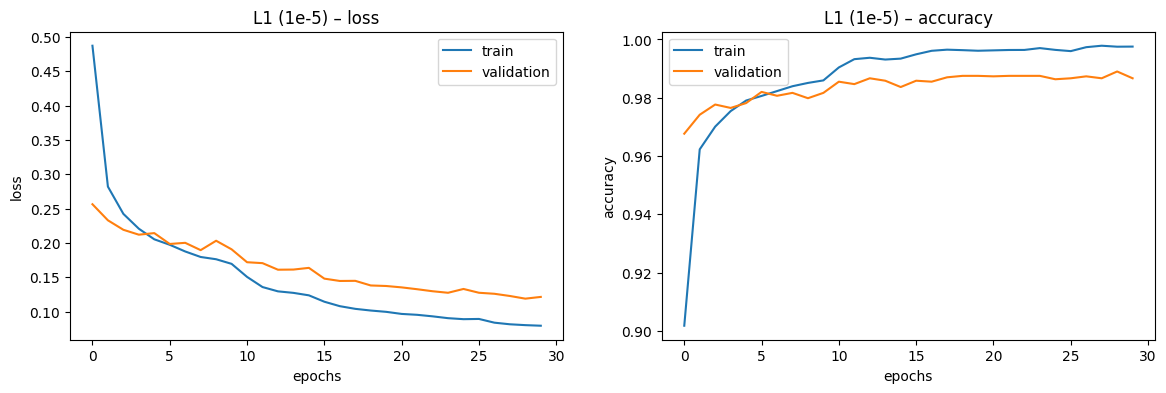

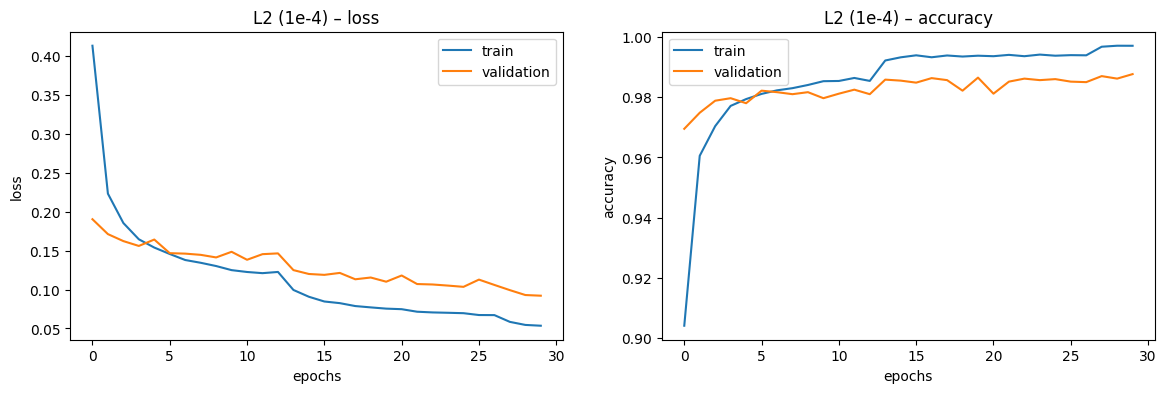

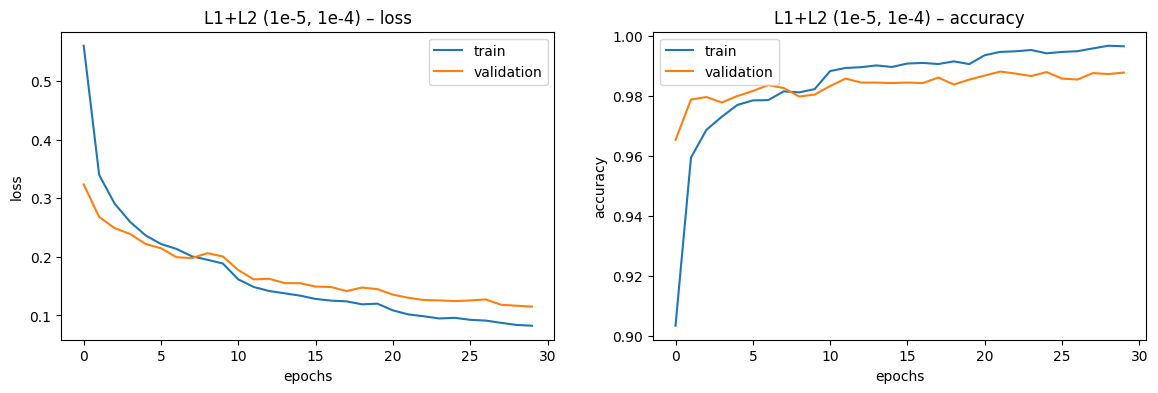

In [17]:
for name, h in reg_histories.items():
    plot_history(h, name)

In [18]:
import pandas as pd
summary = pd.DataFrame(
    [['Baseline (original)', train_info.history['accuracy'][-1], float('nan'), baseline_test_acc],
     ['Improved (no L1/L2)', improved_info.history['accuracy'][-1], improved_info.history['val_accuracy'][-1], improved_acc]] +
    [[f'Improved + {n}', *v] for n, v in reg_results.items()],
    columns=['Model', 'Train accuracy', 'Validation accuracy', 'Test accuracy'])
summary['Train - Test gap'] = summary['Train accuracy'] - summary['Test accuracy']
summary.round(4)

,Model,Train accuracy,Validation accuracy,Test accuracy,Train - Test gap
0,Baseline (original),0.9889,NaN,0.9690,0.0199
1,Improved (no L1/L2),0.9982,0.9882,0.9837,0.0145
2,Improved + L1 (1e-5),0.9975,0.9867,0.9869,0.0106
3,Improved + L2 (1e-4),0.9971,0.9877,0.9847,0.0124
4,"Improved + L1+L2 (1e-5, 1e-4)",0.9966,0.9878,0.9864,0.0102


---
## Part (c) – Class-wise performance with a confusion matrix
The model with the best test accuracy is selected, its predictions on the 10,000 test images are compared to the true labels, and the results are shown as a confusion matrix (rows = true digit, columns = predicted digit).

Best model: Improved + L1 (1e-5)  (test accuracy = 0.9869)


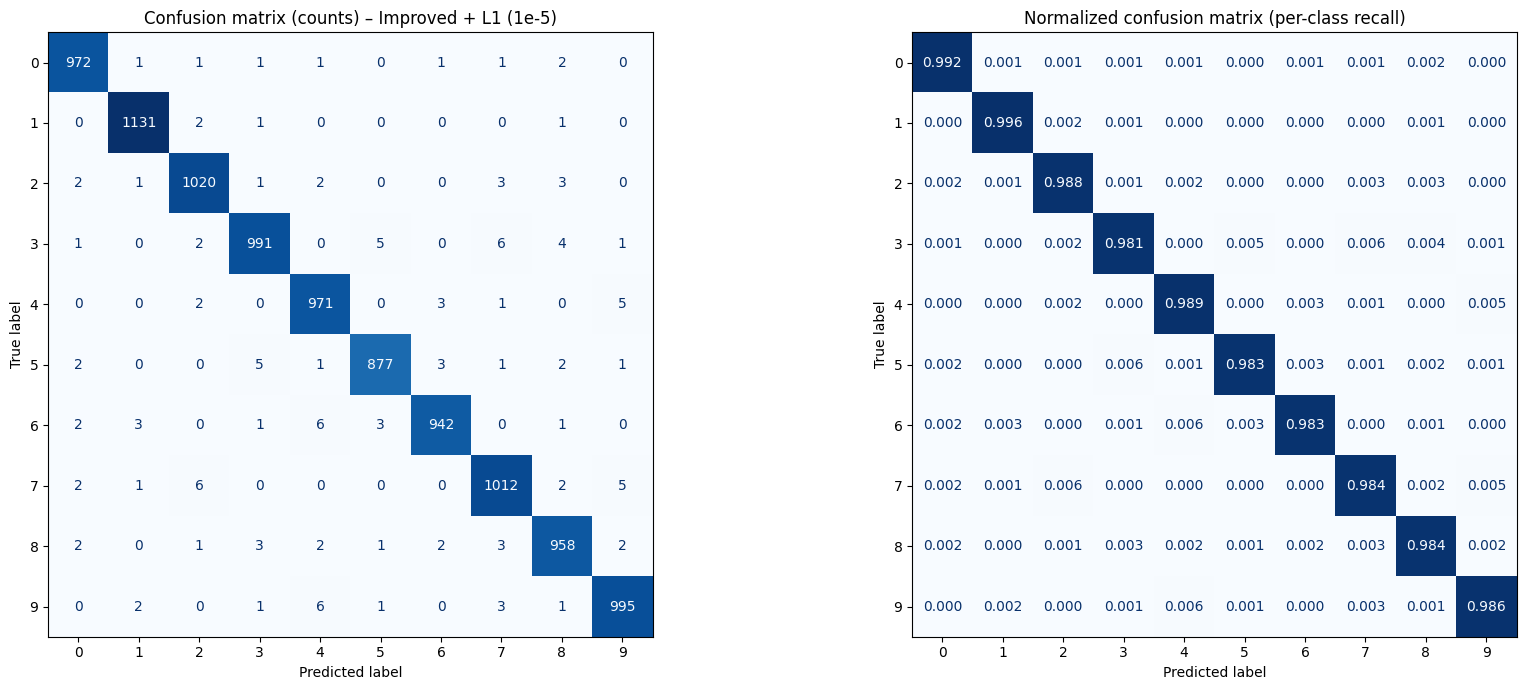

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

candidates = {'Improved (no L1/L2)': improved_model, **{f'Improved + {n}': m for n, m in reg_models.items()}}
test_accs = {'Improved (no L1/L2)': improved_acc, **{f'Improved + {n}': v[2] for n, v in reg_results.items()}}
best_name = max(test_accs, key=test_accs.get)
best_model = candidates[best_name]
print(f'Best model: {best_name}  (test accuracy = {test_accs[best_name]:.4f})')

y_pred = np.argmax(best_model.predict(new_test_data, verbose=0), axis=1)
y_true = test_target
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
ConfusionMatrixDisplay(cm, display_labels=range(10)).plot(ax=ax[0], cmap='Blues', values_format='d', colorbar=False)
ax[0].set_title(f'Confusion matrix (counts) – {best_name}')
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True)
ConfusionMatrixDisplay(cm_norm, display_labels=range(10)).plot(ax=ax[1], cmap='Blues', values_format='.3f', colorbar=False)
ax[1].set_title('Normalized confusion matrix (per-class recall)')
plt.tight_layout()
plt.show()

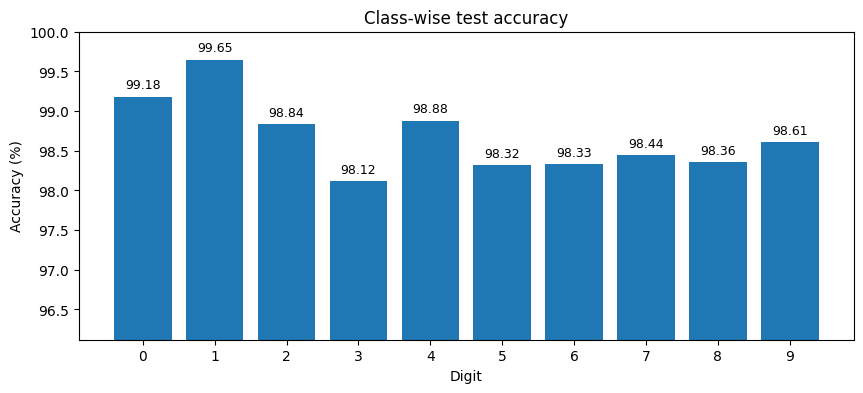

              precision    recall  f1-score   support

           0     0.9888    0.9918    0.9903       980
           1     0.9930    0.9965    0.9947      1135
           2     0.9865    0.9884    0.9874      1032
           3     0.9871    0.9812    0.9841      1010
           4     0.9818    0.9888    0.9853       982
           5     0.9887    0.9832    0.9859       892
           6     0.9905    0.9833    0.9869       958
           7     0.9825    0.9844    0.9835      1028
           8     0.9836    0.9836    0.9836       974
           9     0.9861    0.9861    0.9861      1009

    accuracy                         0.9869     10000
   macro avg     0.9869    0.9867    0.9868     10000
weighted avg     0.9869    0.9869    0.9869     10000

Most frequent confusions (true -> predicted : count)
  7 -> 2 : 6
  6 -> 4 : 6
  9 -> 4 : 6
  3 -> 7 : 6
  5 -> 3 : 5


In [20]:
# Per-class accuracy
per_class_acc = cm.diagonal() / cm.sum(axis=1)
plt.figure(figsize=(10, 4))
bars = plt.bar(range(10), per_class_acc * 100)
plt.ylim(min(per_class_acc) * 100 - 2, 100)
plt.xticks(range(10)); plt.xlabel('Digit'); plt.ylabel('Accuracy (%)')
plt.title('Class-wise test accuracy')
for b, a in zip(bars, per_class_acc):
    plt.text(b.get_x() + b.get_width()/2, a*100 + 0.1, f'{a*100:.2f}', ha='center', fontsize=9)
plt.show()

print(classification_report(y_true, y_pred, digits=4))

# Most common mistakes
off = cm.copy(); np.fill_diagonal(off, 0)
print('Most frequent confusions (true -> predicted : count)')
for idx in np.argsort(off, axis=None)[::-1][:5]:
    t, p = np.unravel_index(idx, off.shape)
    print(f'  {t} -> {p} : {off[t, p]}')

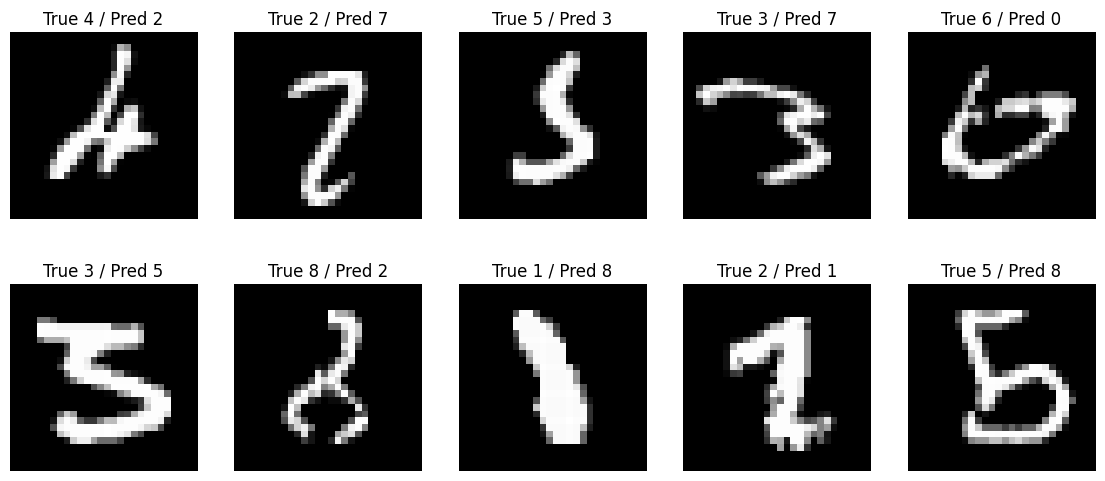

In [21]:
# A few misclassified test images
wrong = np.where(y_pred != y_true)[0]
fig, axs = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axs.ravel(), wrong[:10]):
    ax.imshow(test_data[i], cmap='gray')
    ax.set_title(f'True {y_true[i]} / Pred {y_pred[i]}')
    ax.axis('off')
plt.show()

In [22]:
best_model.save_weights('MNIST_WEIGHTS_IMPROVED.weights.h5')